# Vérification CAD — Modèle de réseau de neurones analogique

Ce notebook implémente et vérifie un modèle de réseau de neurones analogique composé :
- d'un **bloc d'entrée** (Vin → Fin)
- d'un **neurone interne** (Iin → Fspike)
- d'une **synapse excitatrice** (Fpre, Wexc → Iexc)
- d'une **synapse inhibitrice** (Fpre, Winh → Iinh)

## 0. Imports & Configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools

%matplotlib inline

In [2]:
# =========================================================
# FICHIERS
# =========================================================

INPUT_CSV    = "input_min_conso.csv"
NEURON_CSV   = "neuron.csv"
SYN_EXC_CSV  = "excitation20.csv"
SYN_INH_CSV  = "inhibition20.csv"

USE_ZERO_BELOW_NEURON_RANGE = False
FREQ_MERGE_TOL_HZ = 1000.0

## 1. Fonctions utilitaires

In [3]:
# =========================================================
# LECTURE CSV CADENCE
# =========================================================

def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)

    if "Parameter" not in df.columns:
        raise ValueError(f"{csv_path}: colonne 'Parameter' introuvable")

    data_cols = [c for c in df.columns if c not in ["Parameter", "Unnamed: 1"]]

    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df["Parameter"] == row_name, data_cols]
        if row.empty:
            raise ValueError(f"Ligne '{row_name}' introuvable dans {csv_path}")

        values = pd.to_numeric(row.iloc[0], errors="coerce").to_numpy(dtype=float)

        if not allow_non_numeric and np.isnan(values).any():
            bad_idx = np.where(np.isnan(values))[0]
            raise ValueError(
                f"Ligne '{row_name}' dans {csv_path} contient des valeurs non numériques "
                f"aux indices {bad_idx[:10]}"
            )
        return values

    return get_row


def get_clean_rows(reader, row_names):
    """
    Read several rows and keep only columns where ALL requested rows are numeric.
    """
    rows = [reader(name, allow_non_numeric=True) for name in row_names]
    stacked = np.vstack(rows)
    mask = np.all(np.isfinite(stacked), axis=0)
    cleaned = [r[mask] for r in rows]
    return cleaned, mask

In [4]:
# =========================================================
# OUTILS MATHÉMATIQUES
# =========================================================

def interp_clip(x, xp, fp):
    x = np.asarray(x, dtype=float)
    return np.interp(x, xp, fp, left=fp[0], right=fp[-1])


def interp2d_bilinear(x, y, x_axis, y_axis, z_grid):
    x = float(np.clip(x, x_axis[0], x_axis[-1]))
    y = float(np.clip(y, y_axis[0], y_axis[-1]))

    ix = np.searchsorted(x_axis, x) - 1
    iy = np.searchsorted(y_axis, y) - 1

    ix = int(np.clip(ix, 0, len(x_axis) - 2))
    iy = int(np.clip(iy, 0, len(y_axis) - 2))

    x1, x2 = x_axis[ix], x_axis[ix + 1]
    y1, y2 = y_axis[iy], y_axis[iy + 1]

    q11 = z_grid[ix, iy]
    q12 = z_grid[ix, iy + 1]
    q21 = z_grid[ix + 1, iy]
    q22 = z_grid[ix + 1, iy + 1]

    tx = 0.0 if x2 == x1 else (x - x1) / (x2 - x1)
    ty = 0.0 if y2 == y1 else (y - y1) / (y2 - y1)

    return (
        q11 * (1 - tx) * (1 - ty)
        + q21 * tx * (1 - ty)
        + q12 * (1 - tx) * ty
        + q22 * tx * ty
    )


def strictly_monotonic_branch(x, y):
    idx_max = int(np.argmax(y))
    x_m = np.asarray(x[:idx_max + 1], dtype=float)
    y_m = np.asarray(y[:idx_max + 1], dtype=float)

    order = np.argsort(x_m)
    x_m = x_m[order]
    y_m = y_m[order]
    return x_m, y_m


def merge_close_values(values, tol):
    vals = np.sort(np.asarray(values, dtype=float))
    groups = [[vals[0]]]

    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol:
            groups[-1].append(v)
        else:
            groups.append([v])

    return np.array([np.mean(g) for g in groups], dtype=float)


def snap_to_axis(values, axis):
    values = np.asarray(values, dtype=float)
    out = np.empty_like(values, dtype=float)
    for i, v in enumerate(values):
        idx = np.argmin(np.abs(axis - v))
        out[i] = axis[idx]
    return out


def build_grid_tolerant(W_all, F_all, Y_all, freq_tol=1000.0):
    W_all = np.asarray(W_all, dtype=float)
    F_all = np.asarray(F_all, dtype=float)
    Y_all = np.asarray(Y_all, dtype=float)

    W_unique = np.unique(W_all)
    F_axis = merge_close_values(np.unique(F_all), tol=freq_tol)
    F_snap = snap_to_axis(F_all, F_axis)

    z_grid = np.empty((len(W_unique), len(F_axis)), dtype=float)

    for i, w in enumerate(W_unique):
        for j, f in enumerate(F_axis):
            mask = np.isclose(W_all, w) & np.isclose(F_snap, f)
            vals = Y_all[mask]
            if len(vals) == 0:
                raise ValueError(f"Point manquant pour W={w}, Fbin={f}")
            z_grid[i, j] = np.mean(vals)

    return W_unique, F_axis, z_grid

## 2. Chargement des modèles

In [5]:
# =========================================================
# BLOC D'ENTRÉE : Vin -> Fin
# =========================================================

inp = read_cadence_rows(INPUT_CSV)

VEX_IN    = inp("Vex")
FSPIKES_IN = inp("Fspikes")

INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(VEX_IN, FSPIKES_IN)

def input_f_of_v(Vin_V):
    return interp_clip(Vin_V, INPUT_V_AXIS, INPUT_F_AXIS)

print("Bloc d'entrée chargé.")
print(f"  V range : {INPUT_V_AXIS[0]:.4e} V -> {INPUT_V_AXIS[-1]:.4e} V")
print(f"  F range : {INPUT_F_AXIS[0]:.4e} Hz -> {INPUT_F_AXIS[-1]:.4e} Hz")
print(f"  N pts   : {len(INPUT_V_AXIS)}")

Bloc d'entrée chargé.
  V range : -1.0000e-01 V -> 1.0000e-01 V
  F range : 1.0940e+03 Hz -> 5.6000e+04 Hz
  N pts   : 100


In [6]:
# =========================================================
# NEURONE INTERNE : Iin -> Fspike
# =========================================================

neuro = read_cadence_rows(NEURON_CSV)

IEX_NEURO    = neuro("Iex")
FSPIKES_NEURO = neuro("Fspikes")

NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(IEX_NEURO, FSPIKES_NEURO)

def neuron_f_of_i(Iin_A):
    Iin_A = np.asarray(Iin_A, dtype=float)

    if USE_ZERO_BELOW_NEURON_RANGE:
        out = interp_clip(Iin_A, NEURON_I_AXIS, NEURON_F_AXIS)
        out = np.where(Iin_A < NEURON_I_AXIS[0], 0.0, out)
        return out

    return interp_clip(Iin_A, NEURON_I_AXIS, NEURON_F_AXIS)

print("Neurone interne chargé.")
print(f"  I range : {NEURON_I_AXIS[0]:.4e} A -> {NEURON_I_AXIS[-1]:.4e} A")
print(f"  F range : {NEURON_F_AXIS[0]:.4e} Hz -> {NEURON_F_AXIS[-1]:.4e} Hz")
print(f"  N pts   : {len(NEURON_I_AXIS)}")

Neurone interne chargé.
  I range : 3.0000e-12 A -> 1.0000e-09 A
  F range : 3.0830e+03 Hz -> 1.9310e+05 Hz
  N pts   : 100


In [7]:
# =========================================================
# SYNAPSE EXCITATRICE : (Fpre, Wexc) -> Iexc
# =========================================================

syn_exc = read_cadence_rows(SYN_EXC_CSV)

(W2_EXC, FPRE_EXC, IPOST_EXC), mask_exc = get_clean_rows(
    syn_exc, ["W2", "Fpre", "Ipost"]
)
FPOST_EXC = syn_exc("Fpost", allow_non_numeric=True)[mask_exc]

W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID = build_grid_tolerant(
    W2_EXC, FPRE_EXC, IPOST_EXC, freq_tol=FREQ_MERGE_TOL_HZ
)

def isyn_exc(Fpre_Hz, Wexc_um):
    return interp2d_bilinear(Wexc_um, Fpre_Hz, W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID)

print("Synapse excitatrice chargée.")
print(f"  W range : {W_EXC_AXIS[0]:.4f} um -> {W_EXC_AXIS[-1]:.4f} um")
print(f"  F bins  : {F_EXC_AXIS}")
print(f"  Grid    : {IPOST_EXC_GRID.shape}")

Synapse excitatrice chargée.
  W range : 0.1350 um -> 3.0000 um
  F bins  : [  2500.   6750.  12000.  19500.  32000.  50000.  75000. 107750. 145000.
 181500.]
  Grid    : (20, 10)


In [8]:
# =========================================================
# SYNAPSE INHIBITRICE : (Fpre, Winh) -> Iinh
# =========================================================

syn_inh = read_cadence_rows(SYN_INH_CSV)

(W2_INH, FPRE_INH, IPOST_INH), mask_inh = get_clean_rows(
    syn_inh, ["W2", "Fpre", "Ipost"]
)
FPOST_INH = syn_inh("Fpost", allow_non_numeric=True)[mask_inh]

W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID = build_grid_tolerant(
    W2_INH, FPRE_INH, IPOST_INH, freq_tol=FREQ_MERGE_TOL_HZ
)

def isyn_inh(Fpre_Hz, Winh_um):
    return interp2d_bilinear(Winh_um, Fpre_Hz, W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID)

print("Synapse inhibitrice chargée.")
print(f"  W range : {W_INH_AXIS[0]:.4f} um -> {W_INH_AXIS[-1]:.4f} um")
print(f"  F bins  : {F_INH_AXIS}")
print(f"  Grid    : {IPOST_INH_GRID.shape}")

Synapse inhibitrice chargée.
  W range : 0.1350 um -> 1.0000 um
  F bins  : [  2500.   6500.  12000.  19500.  31500.  49500.  75000. 107500. 145000.
 181500.]
  Grid    : (20, 10)


## 3. Chemins élémentaires

In [9]:
# =========================================================
# CHEMIN EXCITATEUR SEUL : Vin -> Fin -> Iexc -> Fpost
# =========================================================

def first_layer_exc_only(Vin_V, Wexc_um):
    Fin_Hz  = float(input_f_of_v(Vin_V))
    Iexc_A  = float(isyn_exc(Fin_Hz, Wexc_um))
    Fpost_Hz = float(neuron_f_of_i(Iexc_A))
    return Fin_Hz, Iexc_A, Fpost_Hz


# =========================================================
# CHEMIN INHIBITEUR SEUL : Vin -> Fin -> Iinh -> Fpost
# =========================================================

def first_layer_inh_only(Vin_V, Winh_um):
    Fin_Hz  = float(input_f_of_v(Vin_V))
    Iinh_A  = float(isyn_inh(Fin_Hz, Winh_um))
    Fpost_Hz = float(neuron_f_of_i(Iinh_A))
    return Fin_Hz, Iinh_A, Fpost_Hz

## 4. Visualisation des modèles

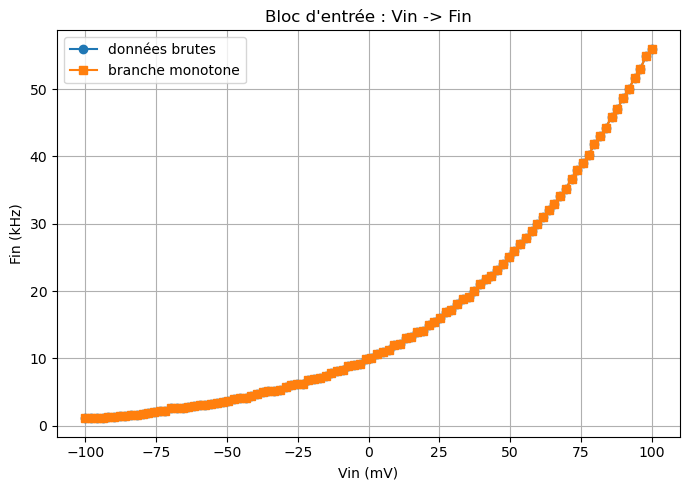

In [10]:
# Bloc d'entrée
plt.figure(figsize=(7, 5))
plt.plot(VEX_IN * 1e3, FSPIKES_IN * 1e-3, "o-", label="données brutes")
plt.plot(INPUT_V_AXIS * 1e3, INPUT_F_AXIS * 1e-3, "s-", label="branche monotone")
plt.xlabel("Vin (mV)")
plt.ylabel("Fin (kHz)")
plt.title("Bloc d'entrée : Vin -> Fin")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

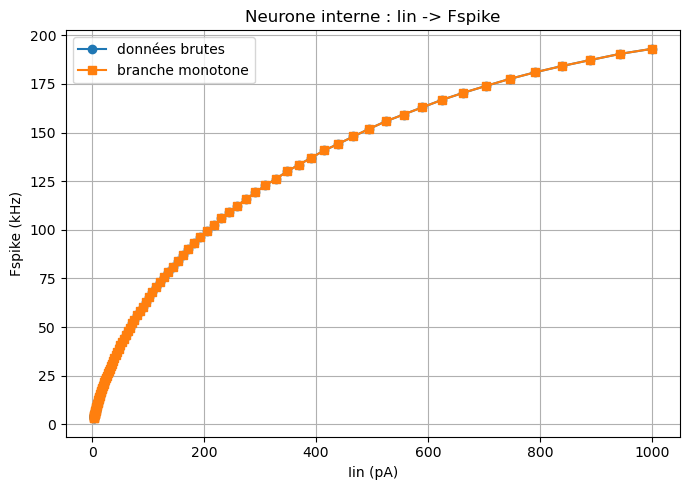

In [11]:
# Neurone interne
plt.figure(figsize=(7, 5))
plt.plot(IEX_NEURO * 1e12, FSPIKES_NEURO * 1e-3, "o-", label="données brutes")
plt.plot(NEURON_I_AXIS * 1e12, NEURON_F_AXIS * 1e-3, "s-", label="branche monotone")
plt.xlabel("Iin (pA)")
plt.ylabel("Fspike (kHz)")
plt.title("Neurone interne : Iin -> Fspike")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

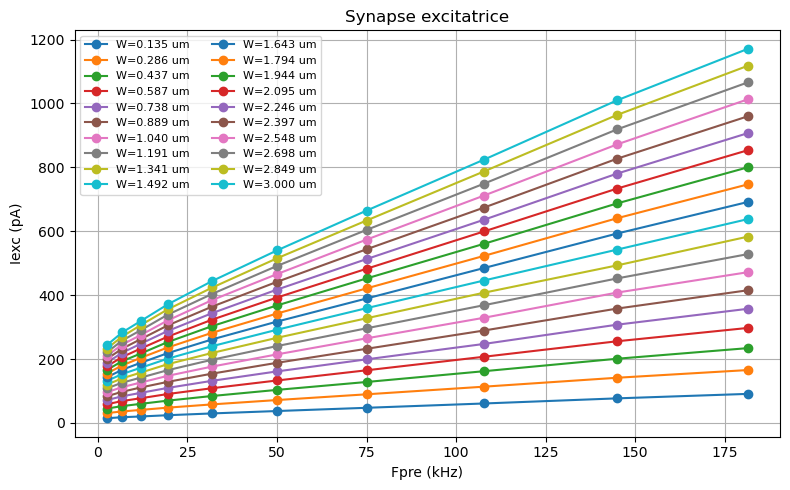

In [12]:
# Synapse excitatrice
plt.figure(figsize=(8, 5))
for i, w in enumerate(W_EXC_AXIS):
    plt.plot(F_EXC_AXIS * 1e-3, IPOST_EXC_GRID[i] * 1e12, "o-", label=f"W={w:.3f} um")
plt.xlabel("Fpre (kHz)")
plt.ylabel("Iexc (pA)")
plt.title("Synapse excitatrice")
plt.grid(True)
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

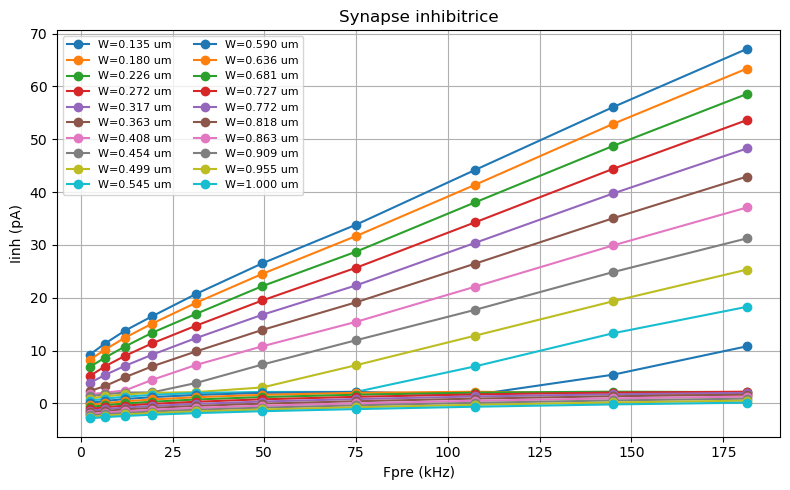

In [13]:
# Synapse inhibitrice
plt.figure(figsize=(8, 5))
for i, w in enumerate(W_INH_AXIS):
    plt.plot(F_INH_AXIS * 1e-3, IPOST_INH_GRID[i] * 1e12, "o-", label=f"W={w:.3f} um")
plt.xlabel("Fpre (kHz)")
plt.ylabel("Iinh (pA)")
plt.title("Synapse inhibitrice")
plt.grid(True)
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

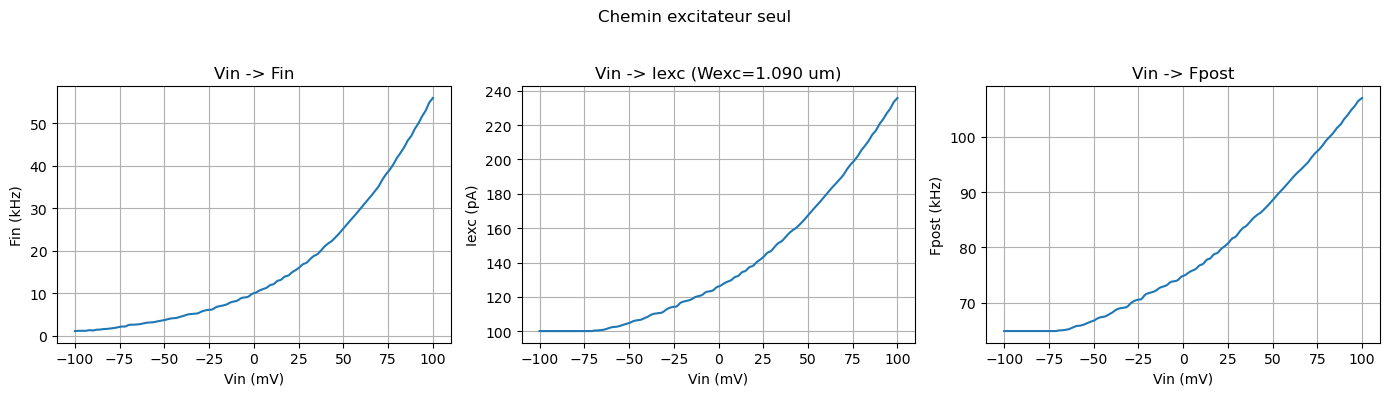

In [14]:
# Réponse chemin excitateur seul
def plot_exc_only_response(Wexc_um=1.09):
    Vin_sweep = np.linspace(INPUT_V_AXIS[0], INPUT_V_AXIS[-1], 200)
    Fin_list, Iexc_list, Fpost_list = [], [], []

    for vin in Vin_sweep:
        Fin, Iexc, Fpost = first_layer_exc_only(vin, Wexc_um)
        Fin_list.append(Fin)
        Iexc_list.append(Iexc)
        Fpost_list.append(Fpost)

    Fin_list   = np.array(Fin_list)
    Iexc_list  = np.array(Iexc_list)
    Fpost_list = np.array(Fpost_list)

    fig, axs = plt.subplots(1, 3, figsize=(14, 4))
    axs[0].plot(Vin_sweep * 1e3, Fin_list * 1e-3)
    axs[0].set_xlabel("Vin (mV)"); axs[0].set_ylabel("Fin (kHz)")
    axs[0].set_title("Vin -> Fin"); axs[0].grid(True)

    axs[1].plot(Vin_sweep * 1e3, Iexc_list * 1e12)
    axs[1].set_xlabel("Vin (mV)"); axs[1].set_ylabel("Iexc (pA)")
    axs[1].set_title(f"Vin -> Iexc (Wexc={Wexc_um:.3f} um)"); axs[1].grid(True)

    axs[2].plot(Vin_sweep * 1e3, Fpost_list * 1e-3)
    axs[2].set_xlabel("Vin (mV)"); axs[2].set_ylabel("Fpost (kHz)")
    axs[2].set_title("Vin -> Fpost"); axs[2].grid(True)

    plt.suptitle("Chemin excitateur seul")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

plot_exc_only_response(Wexc_um=1.09)

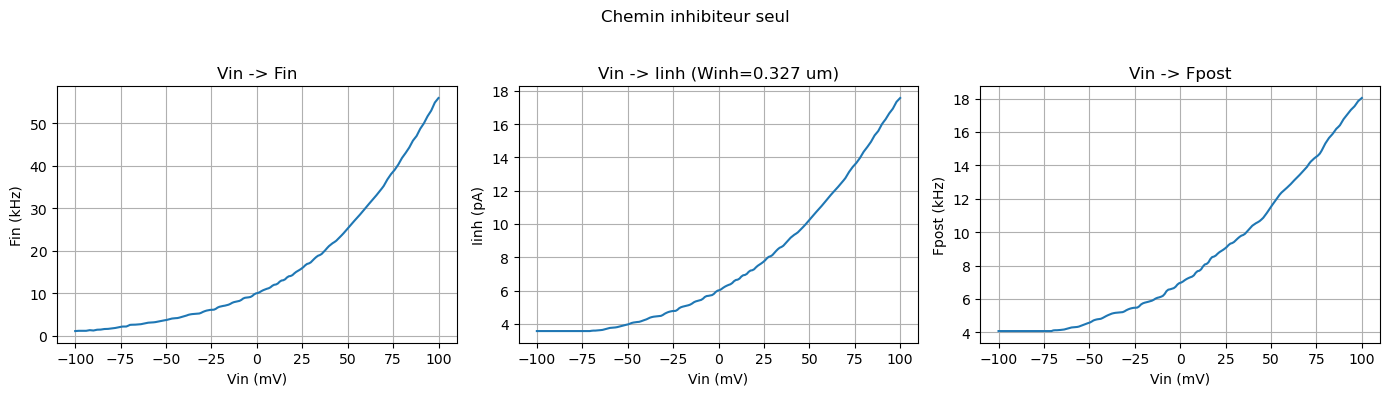

In [15]:
# Réponse chemin inhibiteur seul
def plot_inh_only_response(Winh_um=0.327):
    Vin_sweep = np.linspace(INPUT_V_AXIS[0], INPUT_V_AXIS[-1], 200)
    Fin_list, Iinh_list, Fpost_list = [], [], []

    for vin in Vin_sweep:
        Fin, Iinh, Fpost = first_layer_inh_only(vin, Winh_um)
        Fin_list.append(Fin)
        Iinh_list.append(Iinh)
        Fpost_list.append(Fpost)

    Fin_list   = np.array(Fin_list)
    Iinh_list  = np.array(Iinh_list)
    Fpost_list = np.array(Fpost_list)

    fig, axs = plt.subplots(1, 3, figsize=(14, 4))
    axs[0].plot(Vin_sweep * 1e3, Fin_list * 1e-3)
    axs[0].set_xlabel("Vin (mV)"); axs[0].set_ylabel("Fin (kHz)")
    axs[0].set_title("Vin -> Fin"); axs[0].grid(True)

    axs[1].plot(Vin_sweep * 1e3, Iinh_list * 1e12)
    axs[1].set_xlabel("Vin (mV)"); axs[1].set_ylabel("Iinh (pA)")
    axs[1].set_title(f"Vin -> Iinh (Winh={Winh_um:.3f} um)"); axs[1].grid(True)

    axs[2].plot(Vin_sweep * 1e3, Fpost_list * 1e-3)
    axs[2].set_xlabel("Vin (mV)"); axs[2].set_ylabel("Fpost (kHz)")
    axs[2].set_title("Vin -> Fpost"); axs[2].grid(True)

    plt.suptitle("Chemin inhibiteur seul")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

plot_inh_only_response(Winh_um=0.327)

## 5. Tests unitaires — chemins élémentaires

In [16]:
def print_exc_only_test(Vin_V=50e-3, Wexc_um=1.09):
    Fin, Iexc, Fpost = first_layer_exc_only(Vin_V, Wexc_um)
    print("=== TEST EXCITATEUR SEUL ===")
    print(f"Vin   = {Vin_V:.4e} V")
    print(f"Fin   = {Fin:.4e} Hz")
    print(f"Wexc  = {Wexc_um:.4f} um")
    print(f"Iexc  = {Iexc:.4e} A")
    print(f"Fpost = {Fpost:.4e} Hz")


def print_inh_only_test(Vin_V=50e-3, Winh_um=0.7717):
    Fin, Iinh, Fpost = first_layer_inh_only(Vin_V, Winh_um)
    print("=== TEST INHIBITEUR SEUL ===")
    print(f"Vin   = {Vin_V:.4e} V")
    print(f"Fin   = {Fin:.4e} Hz")
    print(f"Winh  = {Winh_um:.4f} um")
    print(f"Iinh  = {Iinh:.4e} A")
    print(f"Fpost = {Fpost:.4e} Hz")


print_exc_only_test(Vin_V=50e-3, Wexc_um=1.09)
print()
print_inh_only_test(Vin_V=50e-3, Winh_um=0.327)

=== TEST EXCITATEUR SEUL ===
Vin   = 5.0000e-02 V
Fin   = 2.5251e+04 Hz
Wexc  = 1.0900 um
Iexc  = 1.6746e-10 A
Fpost = 8.8550e+04 Hz

=== TEST INHIBITEUR SEUL ===
Vin   = 5.0000e-02 V
Fin   = 2.5251e+04 Hz
Winh  = 0.3270 um
Iinh  = 1.0242e-11 A
Fpost = 1.1519e+04 Hz


## 6. Couche complète : N entrées → M sorties

In [17]:
def layer_forward_1out(Vin_vec_V, sign_vec, width_vec_um):
    """
    Vin_vec_V   : tensions d'entrée, ex [20e-3, 50e-3]
    sign_vec    : +1 si excitatrice, -1 si inhibitrice
    width_vec_um: largeur de chaque synapse

    Retourne:
      Fin_vec_Hz : fréquence de chaque entrée
      Iconn_vec_A: courant de chaque connexion (signé)
      Itot_A     : courant total vers le neurone de sortie
      Fout_Hz    : fréquence du neurone de sortie
    """
    Vin_vec_V    = np.asarray(Vin_vec_V, dtype=float)
    sign_vec     = np.asarray(sign_vec, dtype=int)
    width_vec_um = np.asarray(width_vec_um, dtype=float)

    n = len(Vin_vec_V)
    if len(sign_vec) != n or len(width_vec_um) != n:
        raise ValueError("Vin_vec_V, sign_vec et width_vec_um doivent avoir la même taille")

    Fin_vec_Hz = np.array([float(input_f_of_v(v)) for v in Vin_vec_V], dtype=float)
    Iconn_vec_A = np.zeros(n, dtype=float)

    for i in range(n):
        if sign_vec[i] == 1:
            Iconn_vec_A[i] = float(isyn_exc(Fin_vec_Hz[i], width_vec_um[i]))
        elif sign_vec[i] == -1:
            Iconn_vec_A[i] = -float(isyn_inh(Fin_vec_Hz[i], width_vec_um[i]))
        else:
            raise ValueError("sign_vec doit contenir seulement +1 ou -1")

    Itot_A  = np.sum(Iconn_vec_A)
    Fout_Hz = float(neuron_f_of_i(Itot_A))

    return Fin_vec_Hz, Iconn_vec_A, Itot_A, Fout_Hz


def layer_forward(Vin_vec_V, sign_matrix, width_matrix_um):
    """
    Vin_vec_V       : shape (N,)
    sign_matrix     : shape (N, M), +1 exc, -1 inh
    width_matrix_um : shape (N, M)

    Retourne:
      Fin_vec_Hz    : shape (N,)
      Iconn_mat_A   : shape (N, M)   courants signés
      Itot_vec_A    : shape (M,)
      Fout_vec_Hz   : shape (M,)
    """
    Vin_vec_V       = np.asarray(Vin_vec_V, dtype=float)
    sign_matrix     = np.asarray(sign_matrix, dtype=int)
    width_matrix_um = np.asarray(width_matrix_um, dtype=float)

    N = len(Vin_vec_V)

    if sign_matrix.shape != width_matrix_um.shape:
        raise ValueError("sign_matrix et width_matrix_um doivent avoir la même taille")
    if sign_matrix.shape[0] != N:
        raise ValueError("Le nombre de lignes des matrices doit être égal au nombre d'entrées")

    M = sign_matrix.shape[1]

    Fin_vec_Hz  = np.array([float(input_f_of_v(v)) for v in Vin_vec_V], dtype=float)
    Iconn_mat_A = np.zeros((N, M), dtype=float)

    for i in range(N):
        for j in range(M):
            s = sign_matrix[i, j]
            w = width_matrix_um[i, j]
            if s == 1:
                Iconn_mat_A[i, j] = float(isyn_exc(Fin_vec_Hz[i], w))
            elif s == -1:
                Iconn_mat_A[i, j] = -float(isyn_inh(Fin_vec_Hz[i], w))
            else:
                raise ValueError("sign_matrix doit contenir seulement +1 ou -1")

    Itot_vec_A  = np.sum(Iconn_mat_A, axis=0)
    Fout_vec_Hz = np.array([float(neuron_f_of_i(itot)) for itot in Itot_vec_A], dtype=float)

    return Fin_vec_Hz, Iconn_mat_A, Itot_vec_A, Fout_vec_Hz

In [18]:
def plot_layer_forward_result(Vin_vec_V, Fin_vec_Hz, Iconn_mat_A, Itot_vec_A, Fout_vec_Hz):
    N = len(Vin_vec_V)
    M = len(Itot_vec_A)

    fig, axs = plt.subplots(2, 2, figsize=(11, 8))

    axs[0, 0].bar(np.arange(N), Vin_vec_V * 1e3)
    axs[0, 0].set_title("Entrées")
    axs[0, 0].set_xlabel("Entrée i")
    axs[0, 0].set_ylabel("Vin (mV)")
    axs[0, 0].grid(True, axis="y")

    axs[0, 1].bar(np.arange(N), Fin_vec_Hz * 1e-3)
    axs[0, 1].set_title("Fréquences d'entrée")
    axs[0, 1].set_xlabel("Entrée i")
    axs[0, 1].set_ylabel("Fin (kHz)")
    axs[0, 1].grid(True, axis="y")

    im = axs[1, 0].imshow(Iconn_mat_A * 1e12, aspect="auto", origin="lower")
    axs[1, 0].set_title("Matrice des courants signés")
    axs[1, 0].set_xlabel("Sortie j")
    axs[1, 0].set_ylabel("Entrée i")
    plt.colorbar(im, ax=axs[1, 0], label="Courant (pA)")

    x = np.arange(M)
    axs[1, 1].bar(x - 0.15, Itot_vec_A * 1e12, width=0.3, label="Itot (pA)")
    axs[1, 1].bar(x + 0.15, Fout_vec_Hz * 1e-3, width=0.3, label="Fout (kHz)")
    axs[1, 1].set_title("Sorties")
    axs[1, 1].set_xlabel("Sortie j")
    axs[1, 1].grid(True, axis="y")
    axs[1, 1].legend()

    plt.tight_layout()
    plt.show()

### Test Étape 1 — N entrées → 1 sortie

In [19]:
Vin_vec_V  = np.array([20e-3, 50e-3])
sign_vec   = np.array([1, -1])          # entrée 1 excitatrice, entrée 2 inhibitrice
width_vec_um = np.array([1.09, 0.327])

Fin_vec_Hz, Iconn_vec_A, Itot_A, Fout_Hz = layer_forward_1out(
    Vin_vec_V, sign_vec, width_vec_um
)

print("=== TEST ETAPE 1 : N ENTREES -> 1 SORTIE ===")
print("Vin_vec (mV) =", Vin_vec_V * 1e3)
print("Fin_vec (kHz) =", Fin_vec_Hz * 1e-3)
print("Iconn_vec (pA) =", Iconn_vec_A * 1e12)
print("Itot (pA) =", Itot_A * 1e12)
print("Fout (kHz) =", Fout_Hz * 1e-3)

=== TEST ETAPE 1 : N ENTREES -> 1 SORTIE ===
Vin_vec (mV) = [20. 50.]
Fin_vec (kHz) = [14.43480198 25.25123153]
Iconn_vec (pA) = [138.83156185 -10.24193954]
Itot (pA) = 128.58962231469997
Fout (kHz) = 75.68268427521181


### Test Étape 2 — 2 entrées → 2 sorties

=== TEST ETAPE 2 : 2 ENTREES -> 2 SORTIES ===
Vin_vec (mV) =
[20. 50.]
Fin_vec (kHz) =
[14.43480198 25.25123153]
Iconn_mat (pA) =
[[138.83156185  -7.42078428]
 [ -2.93262631 209.05874596]]
Itot_vec (pA) =
[135.89893554 201.63796168]
Fout_vec (kHz) =
[78.27416805 98.30607673]


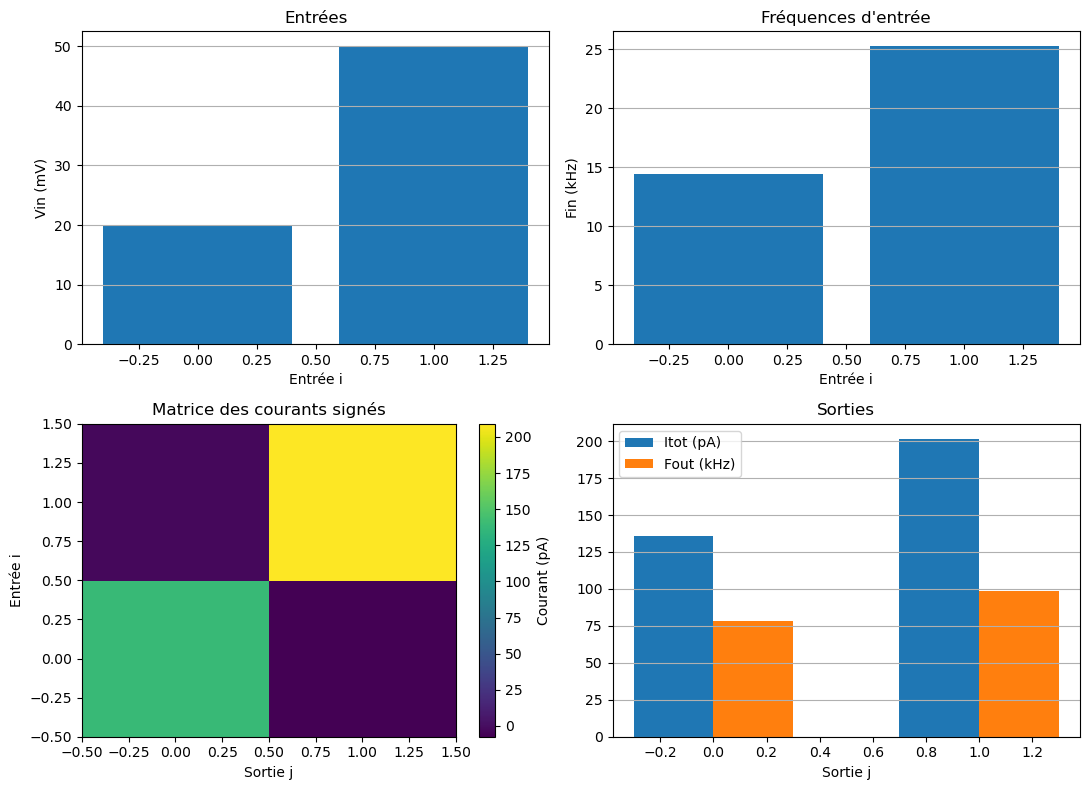

In [20]:
Vin_vec_V = np.array([20e-3, 50e-3])

sign_matrix = np.array([
    [ 1, -1],   # entrée 1 -> sortie 1 exc, sortie 2 inh
    [-1,  1],   # entrée 2 -> sortie 1 inh, sortie 2 exc
])

width_matrix_um = np.array([
    [1.09,  0.325],
    [0.455, 1.410],
])

Fin_vec_Hz, Iconn_mat_A, Itot_vec_A, Fout_vec_Hz = layer_forward(
    Vin_vec_V, sign_matrix, width_matrix_um
)

print("=== TEST ETAPE 2 : 2 ENTREES -> 2 SORTIES ===")
print("Vin_vec (mV) =");    print(Vin_vec_V * 1e3)
print("Fin_vec (kHz) =");   print(Fin_vec_Hz * 1e-3)
print("Iconn_mat (pA) =");  print(Iconn_mat_A * 1e12)
print("Itot_vec (pA) =");   print(Itot_vec_A * 1e12)
print("Fout_vec (kHz) =");  print(Fout_vec_Hz * 1e-3)

plot_layer_forward_result(Vin_vec_V, Fin_vec_Hz, Iconn_mat_A, Itot_vec_A, Fout_vec_Hz)

## 7. Prédiction & Évaluation

In [21]:
def predict_class(Vin_vec_V, sign_matrix, width_matrix_um):
    _, _, _, Fout_vec_Hz = layer_forward(Vin_vec_V, sign_matrix, width_matrix_um)
    pred = int(np.argmax(Fout_vec_Hz))
    return pred, Fout_vec_Hz


def evaluate_dataset(X_list, y_true, sign_matrix, width_matrix_um):
    preds = []
    fout_all = []

    for x in X_list:
        pred, Fout_vec_Hz = predict_class(x, sign_matrix, width_matrix_um)
        preds.append(pred)
        fout_all.append(Fout_vec_Hz)

    preds    = np.array(preds, dtype=int)
    y_true   = np.array(y_true, dtype=int)
    fout_all = np.array(fout_all, dtype=float)

    acc = np.mean(preds == y_true)
    return preds, fout_all, acc


def evaluate_dataset_with_margin(X_list, y_true, sign_matrix, width_matrix_um):
    preds, fout_all, margins = [], [], []

    for x, y in zip(X_list, y_true):
        pred, Fout_vec_Hz = predict_class(x, sign_matrix, width_matrix_um)
        preds.append(pred)
        fout_all.append(Fout_vec_Hz)

        true_score   = Fout_vec_Hz[y]
        other_scores = np.delete(Fout_vec_Hz, y)
        margins.append(true_score - np.max(other_scores))

    preds    = np.array(preds, dtype=int)
    y_true   = np.array(y_true, dtype=int)
    fout_all = np.array(fout_all, dtype=float)
    margins  = np.array(margins, dtype=float)

    acc         = np.mean(preds == y_true)
    mean_margin = np.mean(margins)
    return preds, fout_all, acc, mean_margin

### Test Étape 3 — Prédiction

In [22]:
pred, Fout_vec_Hz = predict_class(Vin_vec_V, sign_matrix, width_matrix_um)

print("=== TEST ETAPE 3 : PREDICTION ===")
print("Fout_vec (kHz) =", Fout_vec_Hz * 1e-3)
print("Predicted class =", pred)

=== TEST ETAPE 3 : PREDICTION ===
Fout_vec (kHz) = [78.27416805 98.30607673]
Predicted class = 1


### Test Étape 4 — Évaluation sur dataset

In [23]:
X_list = np.array([
    [20e-3, 50e-3],   # exemple 0
    [50e-3, 20e-3],   # exemple 1
    [30e-3, 60e-3],   # exemple 2
    [60e-3, 30e-3],   # exemple 3
])

y_true = np.array([1, 0, 1, 0])

preds, fout_all, acc = evaluate_dataset(X_list, y_true, sign_matrix, width_matrix_um)

print("=== TEST ETAPE 4 : DATASET ===")
print("Predictions =", preds)
print("Labels      =", y_true)
print("Accuracy    =", acc)

for k in range(len(X_list)):
    print(f"sample {k}: Fout (kHz) = {fout_all[k]*1e-3}, pred = {preds[k]}, true = {y_true[k]}")

=== TEST ETAPE 4 : DATASET ===
Predictions = [1 0 1 0]
Labels      = [1 0 1 0]
Accuracy    = 1.0
sample 0: Fout (kHz) = [78.27416805 98.30607673], pred = 1, true = 1
sample 1: Fout (kHz) = [87.91778146 87.24187783], pred = 0, true = 0
sample 2: Fout (kHz) = [ 80.92997955 101.88473406], pred = 1, true = 1
sample 3: Fout (kHz) = [91.54752553 90.16577176], pred = 0, true = 0


## 8. Recherche des meilleurs paramètres

In [24]:
def search_best_widths_fixed_signs(X_list, y_true, sign_matrix, width_candidates_um):
    """
    Cherche la meilleure width_matrix pour un sign_matrix fixé.
    width_candidates_um : liste des largeurs autorisées, ex W_EXC_AXIS
    """
    sign_matrix = np.asarray(sign_matrix, dtype=int)
    N, M = sign_matrix.shape

    best_acc = -1.0
    best_width_matrix = None
    best_preds = None
    best_fout  = None

    for combo in itertools.product(width_candidates_um, repeat=N*M):
        width_matrix_um = np.array(combo, dtype=float).reshape(N, M)
        preds, fout_all, acc = evaluate_dataset(
            X_list, y_true, sign_matrix, width_matrix_um
        )
        if acc > best_acc:
            best_acc          = acc
            best_width_matrix = width_matrix_um.copy()
            best_preds        = preds.copy()
            best_fout         = fout_all.copy()

    return best_width_matrix, best_preds, best_fout, best_acc


def search_best_signs_and_widths(X_list, y_true, N, M, width_candidates_um):
    best_score        = -1e99
    best_acc          = -1.0
    best_margin       = None
    best_sign_matrix  = None
    best_width_matrix = None
    best_preds        = None
    best_fout         = None

    n_conn = N * M

    for sign_combo in itertools.product([1, -1], repeat=n_conn):
        sign_matrix = np.array(sign_combo, dtype=int).reshape(N, M)

        for width_combo in itertools.product(width_candidates_um, repeat=n_conn):
            width_matrix_um = np.array(width_combo, dtype=float).reshape(N, M)

            preds, fout_all, acc, mean_margin = evaluate_dataset_with_margin(
                X_list, y_true, sign_matrix, width_matrix_um
            )

            score = acc + 1e-6 * mean_margin

            if score > best_score:
                best_score        = score
                best_acc          = acc
                best_margin       = mean_margin
                best_sign_matrix  = sign_matrix.copy()
                best_width_matrix = width_matrix_um.copy()
                best_preds        = preds.copy()
                best_fout         = fout_all.copy()

    return best_sign_matrix, best_width_matrix, best_preds, best_fout, best_acc, best_margin

### Test Étape 5 — Recherche des meilleures largeurs (signes fixés)

In [25]:
width_candidates_um = W_EXC_AXIS   # mêmes largeurs disponibles pour la recherche

best_width_matrix, best_preds, best_fout, best_acc = search_best_widths_fixed_signs(
    X_list, y_true, sign_matrix, width_candidates_um
)

print("=== TEST ETAPE 5 : SEARCH BEST WIDTHS ===")
print("Best width matrix (um) =")
print(best_width_matrix)
print("Best predictions =", best_preds)
print("Best accuracy    =", best_acc)

for k in range(len(X_list)):
    print(f"sample {k}: Fout (kHz) = {best_fout[k]*1e-3}, pred = {best_preds[k]}, true = {y_true[k]}")

=== TEST ETAPE 5 : SEARCH BEST WIDTHS ===
Best width matrix (um) =
[[0.135 0.135]
 [0.135 0.135]]
Best predictions = [1 0 1 0]
Best accuracy    = 1.0
sample 0: Fout (kHz) = [ 3.21630505 13.47321376], pred = 1, true = 1
sample 1: Fout (kHz) = [13.47321376  3.21630505], pred = 0, true = 0
sample 2: Fout (kHz) = [ 3.083      14.40434204], pred = 1, true = 1
sample 3: Fout (kHz) = [14.40434204  3.083     ], pred = 0, true = 0


### Test Étape 7 — Recherche des meilleurs signes + largeurs + marge

In [26]:
N = 2
M = 2
width_candidates_um = np.array([0.135, 1.09, 2.045, 3.0])

best_sign_matrix, best_width_matrix, best_preds, best_fout, best_acc, best_margin = \
    search_best_signs_and_widths(X_list, y_true, N, M, width_candidates_um)

print("=== TEST ETAPE 7 : SEARCH BEST SIGNS + WIDTHS + MARGIN ===")
print("Best sign matrix =")
print(best_sign_matrix)
print("Best width matrix (um) =")
print(best_width_matrix)
print("Best predictions =", best_preds)
print("Best accuracy    =", best_acc)
print("Best mean margin =", best_margin)

for k in range(len(X_list)):
    print(f"sample {k}: Fout (kHz) = {best_fout[k]*1e-3}, pred = {best_preds[k]}, true = {y_true[k]}")

=== TEST ETAPE 7 : SEARCH BEST SIGNS + WIDTHS + MARGIN ===
Best sign matrix =
[[ 1 -1]
 [-1  1]]
Best width matrix (um) =
[[3.    0.135]
 [0.135 3.   ]]
Best predictions = [1 0 1 0]
Best accuracy    = 1.0
Best mean margin = 13079.859167645256
sample 0: Fout (kHz) = [124.31976092 136.88816497], pred = 1, true = 1
sample 1: Fout (kHz) = [136.88816497 124.31976092], pred = 0, true = 0
sample 2: Fout (kHz) = [127.78103014 141.37234443], pred = 1, true = 1
sample 3: Fout (kHz) = [141.37234443 127.78103014], pred = 0, true = 0
